# The data model

This page explains how a mesh is stored in memory: which objects make up a `PolyData`, what each of
them owns, and how they find each other. The classes involved live in three subpackages:

| Subpackage | What it holds | Main classes |
|---|---|---|
| `sigmaepsilon.mesh.data` | containers and data storage | `PolyData`, `PointData`, `CellData`, `PolyCell`, `LineData`, `TriMesh` |
| `sigmaepsilon.mesh.cells` | concrete cell types | `L2`, `T3`, `Q4`, `H8`, `TET4`, ... |
| `sigmaepsilon.mesh.geometry` | class-level descriptions of cell shapes | `PolyCellGeometry`, `PolyCellGeometry1d/2d/3d` |

In one sentence: a mesh is a **tree of `PolyData` blocks**; a block may own a **`PointData`** (the
points) and a **`PolyCell`** (the cells); a `PolyCell` keeps its numbers in a **`CellData`** and
knows its shape through a nested **`Geometry`** class.

The diagram below is the map for the rest of the page. Solid diamonds mean ownership, plain
arrows inheritance, and dashed arrows references to objects owned by someone else.

## A running example

We use one small mesh throughout the page: six points shared by two triangles, one quadrilateral
and two lines. The triangles and the quad are grouped under a block called `"surface"`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sigmaepsilon.mesh import PolyData, PointData, CartesianFrame
from sigmaepsilon.mesh.cells import T3, Q4, L2

coords = np.array(
    [
        [0.0, 0.0, 0.0],
        [1.0, 0.0, 0.0],
        [1.0, 1.0, 0.0],
        [0.0, 1.0, 0.0],
        [2.0, 0.0, 0.0],
        [2.0, 1.0, 0.0],
    ]
)
frame = CartesianFrame(dim=3)

mesh = PolyData(PointData(coords=coords, frame=frame))
mesh["surface"]["tri"] = PolyData(cd=T3(topo=np.array([[0, 1, 2], [0, 2, 3]])))
mesh["surface"]["quad"] = PolyData(cd=Q4(topo=np.array([[1, 4, 5, 2]])))
mesh["edges"] = PolyData(cd=L2(topo=np.array([[0, 4], [3, 5]])))

The figure shows the point indices (black), and for every cell its block and its global cell
index. The topology of every block refers to the same six points, which belong to the root.

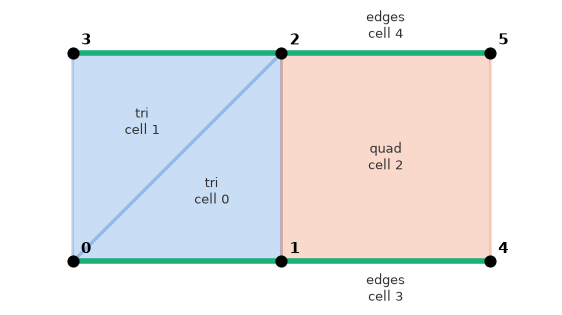

In [2]:
COLORS = {"tri": "#2a78d6", "quad": "#eb6834", "edges": "#1baf7a"}


def draw_mesh(mesh, ax):
    x = mesh.pd.x
    for block in mesh.cellblocks(inclusive=True):
        name = block.key
        color = COLORS[name]
        topo = block.cd.topology().to_numpy()
        for cid, cell in zip(block.cd.id, topo):
            pts = x[cell, :2]
            if len(cell) == 2:
                ax.plot(*pts.T, color=color, lw=4, zorder=3, solid_capstyle="round")
                cx, cy = 0.25 * pts[0] + 0.75 * pts[1]
                cy += 0.13 if cy > 0.5 else -0.13
            else:
                ax.fill(*pts.T, facecolor=color, alpha=0.25, edgecolor=color, lw=2)
                cx, cy = pts.mean(axis=0)
            ax.text(cx, cy, f"{name}\ncell {cid}", ha="center", va="center",
                    fontsize=9, color="#333333")
    ax.scatter(x[:, 0], x[:, 1], s=60, color="black", zorder=4)
    for i, (px, py, _) in enumerate(x):
        ax.annotate(str(i), (px, py), xytext=(6, 6), textcoords="offset points",
                    fontsize=11, fontweight="bold")
    ax.set_aspect("equal")
    ax.margins(0.15)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(7, 3.6))
draw_mesh(mesh, ax)
plt.show()

## `PolyData`: a tree of blocks

`PolyData` is a subclass of `DeepDict` from `sigmaepsilon.deepdict`, which is itself a `dict`. Every
value in it is another `PolyData`, so a mesh is a tree. Each node of the tree is called a **block**
(or a **container**), and every block can:

- hold a `PointData` (`block.pd`), a set of points,
- hold a `PolyCell` (`block.cd`), a set of cells of a single type,
- hold child blocks,
- or any combination of these. Pure grouping blocks, like `"surface"` here, hold neither points nor cells.

The tree of the example looks like this:

Since it is a dictionary, the usual dictionary operations work, and every block knows its place
in the tree:

In [3]:
isinstance(mesh, dict), list(mesh.keys()), list(mesh["surface"].keys())

(True, ['surface', 'edges'], ['tri', 'quad'])

In [4]:
quad = mesh["surface"]["quad"]
quad.address, quad.parent is mesh["surface"], quad.root is mesh, mesh.is_root()

(['surface', 'quad'], True, True, True)

To walk the tree, use `blocks`, or the filtered versions `pointblocks` (blocks with a `PointData`)
and `cellblocks` (blocks with a `PolyCell`). With `inclusive=True` the block the call is made on is
included too.

In [5]:
print("cell blocks :", [b.address for b in mesh.cellblocks(inclusive=True)])
print("point blocks:", [b.address for b in mesh.pointblocks(inclusive=True)])

cell blocks : [['surface', 'tri'], ['surface', 'quad'], ['edges']]
point blocks: [[]]


The root has an empty address, which is why the point block shows up as `[]`.

Mesh-level methods such as `coords()`, `topology()`, `areas()` or `plot()` work on any block and
collect their data from the blocks below it, so `mesh["surface"]` can be used as a mesh of its own:

In [6]:
mesh.topology()

<Array [[0, 1, 2], [0, 2, 3], ..., [0, 4], [3, 5]] type='5 * var * int64'>

In [7]:
mesh["surface"].topology()

<Array [[0, 1, 2], [0, 2, 3], [1, 4, 5, 2]] type='3 * var * int64'>

Besides `pd` and `cd`, a block holds a few more things:

- `config`: a `DeepDict` of plotting settings, looked up by the plotting functions,
- `celltype`: the class of its cells (`Q4` for the quad block), or `None`,
- on the root only, two index managers (`pim` for points, `cim` for cells) that hand out global
  indices (see [Global indices](#Global-indices) below).

In [8]:
quad.celltype, mesh["surface"].celltype, quad.config

(sigmaepsilon.mesh.cells.q4.Q4,
 None,
 DeepDict({'pv': DeepDict({'default': DeepDict({'show_edges': True})})}))

## `PointData`: the points

A `PointData` stores the points of a block and everything attached to them. It is a thin wrapper
(`AkWrapper`) around an **Awkward array** with one record per point. The wrapped array is available
as `pd.db`:

In [9]:
pd = mesh.pd
type(pd).__name__, type(pd.db).__name__, len(pd)

('PointData', 'Array', 6)

In [10]:
pd.db

<Array [{__x: [0, ..., 0], ...}, ..., {...}] type='6 * {__x: 3 * float64, _...'>

Every field of the record is a column with one entry per point. The fields the library itself uses
have reserved names starting with two underscores, and they are reached through properties:

| Property | Field | Content |
|---|---|---|
| `pd.x` | `__x` | coordinates, `(nP, nD)` float array |
| `pd.id` | `__id` | global point indices, set when the block joins a mesh |
| `pd.activity` | `__activity` | optional boolean flags |

The coordinates are understood in the frame `pd.frame`, a `CartesianFrame` from
`sigmaepsilon.math.linalg`. A block that has no points of its own inherits the frame of its
closest ancestor that has some (`block.frame`).

In [11]:
pd.db.fields, pd.x.shape, pd.id

(['__x', '__id'], (6, 3), array([0, 1, 2, 3, 4, 5]))

In [12]:
pd.frame is frame, quad.frame is frame

(True, True)

Your own data goes into the same record. Any array with one row per point can be attached with
`pd.db[key] = value`; rows can themselves be vectors or tensors:

In [13]:
pd.db["temperature"] = np.linspace(20.0, 30.0, len(pd))
pd.db["displacement"] = np.zeros((len(pd), 3))
pd.db.fields

['__x', '__id', 'temperature', 'displacement']

In [14]:
pd.db["temperature"].to_numpy()

array([20., 22., 24., 26., 28., 30.])

Finally, every `PointData` knows the block that owns it, through `pd.container`. This back
reference is what lets point-level operations (for example `pd.pull`, which collects data from the
cells) reach the rest of the mesh.

In [15]:
pd.container is mesh

True

## Cells: `PolyCell` and `CellData`

Cells are split over two objects with different jobs:

- **`CellData`** is the *storage*. Like `PointData`, it wraps an Awkward array, with one record per
  cell: the topology, the global cell indices, the cell frames, thicknesses, and your own fields.
- **`PolyCell`** is the *cell type*: the class you actually instantiate (`T3`, `Q4`, `H8`, ...). It
  owns a `CellData` (`cd.db`), knows which points its topology refers to (`cd.pd`) and which block
  owns it (`cd.container`), and carries a nested `Geometry` class that describes the shape of the
  cell. All the geometric methods (`measures`, `centers`, `jacobian_matrix`, `loc_to_glob`, `pip`,
  `to_vtk`, ...) live here.

So when you write `Q4(topo=...)`, the arguments are forwarded to the class in `Q4.data_class`
(`CellData` by default), and the `Q4` instance wraps the result:

In [16]:
cd = quad.cd
type(cd).__name__, type(cd.db).__name__, type(cd.db.db).__name__

('Q4', 'CellData', 'Array')

In [17]:
cd.db.db

<Array [{_topology: [1, ...], _id: 2}] type='1 * {_topology: 4 * int64, _id...'>

The reserved fields of a `CellData` start with a single underscore, and properties translate the
public names through a class attribute called `_attr_map_`:

In [18]:
from sigmaepsilon.mesh.data import CellData

CellData._attr_map_

{'nodes': '_topology',
 'frames': '_frames',
 'ndf': '_ndf',
 'id': '_id',
 'areas': '_areas',
 't': '_t',
 'activity': '_activity'}

A `PolyCell` forwards every attribute it doesn't have to its `CellData`, and `CellData` forwards
unknown attributes to the Awkward array. That is why `cd.nodes`, `cd.db.nodes` and the raw field
all give the same topology:

In [19]:
np.array_equal(cd.nodes, cd.db.nodes), np.array_equal(cd.nodes, cd.db.db["_topology"].to_numpy())

(True, True)

Methods of `PolyCell` usually return richer objects than the raw columns. `topology()` wraps the
node indices in a `TopologyArray`, a container that also supports jagged topologies:

In [20]:
type(cd.topology()).__name__, cd.topology()

('TopologyArray', array([[1, 4, 5, 2]]))

Some fields are filled lazily. The cell frames (local coordinate systems) are only computed, from
the coordinates and the geometry of the cells, when you first ask for them, and they are then stored
in the `_frames` field:

In [21]:
print("before:", mesh["edges"].cd.db.fields)
frames = mesh["edges"].cd.frames  # (nE, 3, 3), the axes of a frame per cell
print("after :", mesh["edges"].cd.db.fields)
frames[0]

before: ['_topology', '_id']
after : ['_topology', '_id', '_frames']


array([[ 1.,  0.,  0.],
       [ 0.,  0., -1.],
       [ 0.,  1.,  0.]])

User data on cells works as on points, with one row per cell. One value per cell is a scalar
field; one value per cell node, shaped `(nE, nNE)`, is data given at the nodes of every cell.

In [22]:
tri = mesh["surface"]["tri"]
tri.cd.db["pressure"] = np.array([1.0, 2.0])
tri.cd.db.fields

['_topology', '_id', 'pressure']

### Which points does a cell block refer to?

The topology of a cell block holds indices into a `PointData` that isn't necessarily owned by the
same block: here every cell block refers to the points of the root. That block is found with
`block.source()` (or `cd.source()`), which walks up the tree and returns the closest block, the block
itself included, that has a `PointData` with coordinates. This is the lookup the geometric methods
of `PolyCell` use.

`cd.pd` is a shortcut to the same `PointData`, set when the block is created or joins a tree. It
can be `None` (see [Several point clouds in one mesh](#Several-point-clouds-in-one-mesh)), so treat
`source()` as the authoritative answer.

In [23]:
quad.pd is None, quad.cd.pd is mesh.pd, quad.source() is mesh

(True, True, True)

## `Geometry`: the shape of a cell

Every cell type has a nested class called `Geometry`. It holds **no data about any particular
cell**: everything on it is a class attribute or a class method describing the *master element*,
the reference cell in natural coordinates. The base classes live in
`sigmaepsilon.mesh.geometry`:

For the quadrilateral:

In [24]:
G = Q4.Geometry
print(G.__mro__[1].__name__)
print("nodes:", G.number_of_nodes, "| spatial dims:", G.number_of_spatial_dimensions,
      "| VTK id:", G.vtk_cell_id)
print("master coordinates:\n", G.master_coordinates())
print("shape functions at the center:", G.shape_function_values(np.array([[0.0, 0.0]])))

PolyCellGeometry2d
nodes: 4 | spatial dims: 2 | VTK id: 9
master coordinates:
 [[-1. -1.]
 [ 1. -1.]
 [ 1.  1.]
 [-1.  1.]]
shape functions at the center: [[0.25 0.25 0.25 0.25]]


The cell classes in `sigmaepsilon.mesh.cells` are mostly just a `label` and a `Geometry`; all the
behaviour is inherited from `PolyCell`. The table below is generated from the classes themselves:

In [25]:
import pandas
from sigmaepsilon.mesh import cells

rows = []
for name in ["L2", "L3", "T3", "T6", "Q4", "Q8", "Q9", "TET4", "TET10", "H8", "H27", "W6", "W18"]:
    C = getattr(cells, name)
    G = C.Geometry
    rows.append(
        {
            "cell": name,
            "Geometry base": G.__mro__[1].__name__,
            "nodes": G.number_of_nodes,
            "VTK id": G.vtk_cell_id,
            "quadratures": ", ".join(G.quadrature or {}),
        }
    )
pandas.DataFrame(rows).set_index("cell")

,Geometry base,nodes,VTK id,quadratures
cell,,,,
L2,PolyCellGeometry1d,2,3,"full, geometry"
L3,PolyCellGeometry1d,3,21,"full, geometry"
T3,PolyCellGeometry2d,3,5,"full, geometry"
T6,PolyCellGeometry2d,6,22,"full, geometry"
Q4,PolyCellGeometry2d,4,9,"full, geometry"
Q8,PolyCellGeometry2d,8,23,"full, geometry"
Q9,PolyCellGeometry2d,9,28,"full, geometry"
TET4,PolyCellGeometry3d,4,10,"full, geometry"
TET10,PolyCellGeometry3d,10,24,"full, geometry"


A `PolyCell` combines the class-level `Geometry` with the per-cell data. For example, `loc_to_glob`
evaluates the shape functions of the master element (from `Geometry`) and multiplies them with the
coordinates of the nodes of every cell (from `cd.pd` and the topology in `cd.db`). The figure maps a
grid of natural coordinates $(r, s)$ of the master `Q4` onto a distorted quadrilateral:

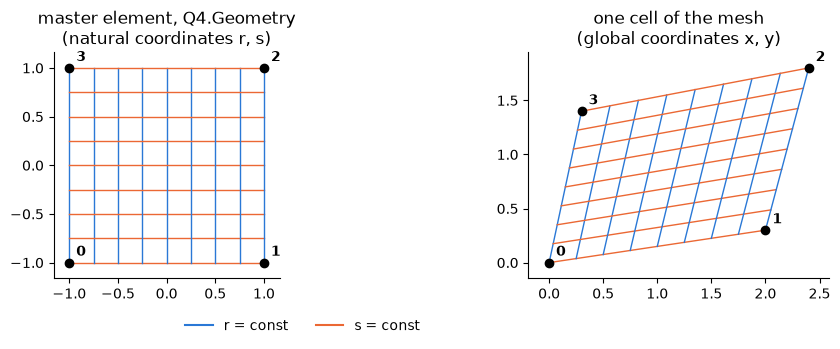

In [26]:
xq = np.array([[0.0, 0.0, 0.0], [2.0, 0.3, 0.0], [2.4, 1.8, 0.0], [0.3, 1.4, 0.0]])
qcell = PolyData(PointData(coords=xq, frame=frame), Q4(topo=np.array([[0, 1, 2, 3]])))

t = np.linspace(-1, 1, 41)
levels = np.linspace(-1, 1, 9)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.8))
for v in levels:
    # lines of constant r and constant s in natural coordinates
    r_line = np.column_stack([np.full_like(t, v), t])
    s_line = np.column_stack([t, np.full_like(t, v)])
    ax1.plot(*r_line.T, color="#2a78d6", lw=1)
    ax1.plot(*s_line.T, color="#eb6834", lw=1)
    # the same lines, mapped by the shape functions of Q4.Geometry
    X_r = qcell.cd.loc_to_glob(r_line)[0]
    X_s = qcell.cd.loc_to_glob(s_line)[0]
    ax2.plot(X_r[:, 0], X_r[:, 1], color="#2a78d6", lw=1)
    ax2.plot(X_s[:, 0], X_s[:, 1], color="#eb6834", lw=1)

master = Q4.Geometry.master_coordinates()
for i, (a, b) in enumerate(master):
    ax1.annotate(str(i), (a, b), xytext=(5, 5), textcoords="offset points", fontweight="bold")
for i, (a, b, _) in enumerate(xq):
    ax2.annotate(str(i), (a, b), xytext=(5, 5), textcoords="offset points", fontweight="bold")
ax1.scatter(*master.T, color="black", zorder=3)
ax2.scatter(xq[:, 0], xq[:, 1], color="black", zorder=3)

ax1.set_title("master element, Q4.Geometry\n(natural coordinates r, s)")
ax2.set_title("one cell of the mesh\n(global coordinates x, y)")
ax1.plot([], [], color="#2a78d6", label="r = const")
ax1.plot([], [], color="#eb6834", label="s = const")
ax1.legend(loc="lower center", bbox_to_anchor=(1.1, -0.3), ncol=2, frameon=False)
for ax in (ax1, ax2):
    ax.set_aspect("equal")
    ax.margins(0.08)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

The same split shows up everywhere: `measures()`, `jacobian_matrix()`, `centers()`, `to_triangles()`
or `to_vtk()` all read a recipe from `Geometry` (shape function derivatives, quadrature rules,
triangulation maps, VTK cell ids) and apply it to the arrays in `CellData`.

Two more things happen at class level:

- When a `PolyCell` subclass with a `Geometry` is defined, its metaclass checks that the geometry
  implements the `GeometryProtocol` (in `sigmaepsilon.mesh.typing`), and registers the cell class
  under its VTK and meshio cell ids. That registry is how `PolyData.read`, `from_pv` and
  `from_meshio` know which cell class to build for an imported block.
- `PolyCellGeometry.generate_class` creates new geometry classes on the fly, for example for custom
  Lagrange cells whose shape functions are generated symbolically (see
  [Shape function generation](shape_function_generation.ipynb)).

In [27]:
from sigmaepsilon.mesh.helpers import vtk_to_celltype

{k: v.__name__ for k, v in sorted(vtk_to_celltype.items())}

{3: 'L2',
 5: 'T3',
 9: 'Q4',
 10: 'TET4',
 12: 'H8',
 13: 'W6',
 21: 'L3',
 22: 'T6',
 23: 'Q8',
 24: 'TET10',
 28: 'Q9',
 29: 'H27',
 32: 'W18'}

## Several point clouds in one mesh

Points don't have to live at the root. Any block can have its own `PointData`, and the cells below
it then refer to those points. `source()` resolves this for every cell block:

In [28]:
def square(x0):
    return np.array([[x0, 0, 0], [x0 + 1, 0, 0], [x0 + 1, 1, 0], [x0, 1, 0]], dtype=float)


multi = PolyData()
multi["a"] = PolyData(PointData(coords=square(0.0)), T3(topo=np.array([[0, 1, 2], [0, 2, 3]])))
multi["b"] = PolyData(PointData(coords=square(2.0)), Q4(topo=np.array([[0, 1, 2, 3]])))

print("root has points:", multi.pd is not None)
for b in multi.cellblocks():
    print(b.key, "| source:", b.source().address, "| topology:", b.cd.nodes.tolist())

root has points: False
a | source: ['a'] | topology: [[0, 1, 2], [0, 2, 3]]
b | source: ['b'] | topology: [[0, 1, 2, 3]]


`to_standard_form()` moves all points into a single `PointData` at the root and rewrites the
topologies to index into it. It also clears the `cd.pd` shortcut of the cell blocks, which from
then on reach the merged points through `source()`. Many algorithms (nodal adjacency, nodal distribution of data,
exports) expect this standard form.

In [29]:
multi.to_standard_form()

print("root points:", len(multi.pd))
for b in multi.cellblocks():
    print(b.key, "| own pd:", b.pd is not None, "| source is root:", b.source() is multi,
          "| cd.pd:", b.cd.pd, "| topology:", b.cd.nodes.tolist())

root points: 8
a | own pd: False | source is root: True | cd.pd: None | topology: [[0, 1, 2], [0, 2, 3]]
b | own pd: False | source is root: True | cd.pd: None | topology: [[4, 5, 6, 7]]


## Global indices

Every point and every cell in a mesh has a global index, stored in the `__id` and `_id` fields.
The indices are handed out by two `IndexManager` objects on the root (`pim` and `cim`). When a block
is created on its own, it is a root and gets indices from its own managers. When it is inserted into
a tree, the `DeepDict` hook `__after_join_parent__` re-indexes the block and everything below it
against the new root, and points the cells to their new source:

In [30]:
new = PolyData(cd=L2(topo=np.array([[1, 3]])))
print("ids while standalone:", new.cd.id)

mesh["diagonal"] = new
print("ids after joining   :", new.cd.id)
print("all cell ids        :", [b.cd.id.tolist() for b in mesh.cellblocks()])

ids while standalone: [0]
ids after joining   : [5]
all cell ids        : [[0, 1], [2], [3, 4], [5]]


Removing a block does the reverse: its indices are returned to the root's managers and deleted from
the block, which becomes a root with fresh managers of its own.

In [31]:
del mesh["diagonal"]
print("has ids after leaving:", new.cd.db.has_id)

has ids after leaving: False


## Specialised containers

`LineData` and `TriMesh` are subclasses of `PolyData` with some extra behaviour for meshes of lines
(plotting with Plotly, tube-like rendering) and of triangles (normals, planarity checks, extrusion to
tetrahedra). They store their data exactly the same way.

The interfaces of the data classes are also described as `typing.Protocol`s in
`sigmaepsilon.mesh.typing` (`PolyDataProtocol`, `PointDataProtocol`, `CellDataProtocol`,
`PolyCellProtocol`, `GeometryProtocol`). The data classes type their references to each other
against these protocols rather than the concrete classes, so that other packages, such as
`sigmaepsilon.solid.fem`, can plug in their own subclasses.

## Summary: where does everything live?

| What | Where | Owned by |
|---|---|---|
| the tree of blocks | `PolyData` (a `DeepDict`) | the root |
| coordinates | `block.pd.db["__x"]`, via `block.pd.x` | the source block of the cells |
| frame of the points | `block.pd.frame`, resolved by `block.frame` | `PointData` |
| point data | `block.pd.db[key]` | `PointData` |
| topology | `block.cd.db.db["_topology"]`, via `block.cd.nodes` or `block.cd.topology()` | `CellData` |
| cell frames, thickness, areas | `block.cd.frames`, `block.cd.t`, `block.cd.A` | `CellData` |
| cell data | `block.cd.db[key]` | `CellData` |
| points the topology refers to | `block.source().pd` (shortcut: `block.cd.pd`, may be `None`) | the source block |
| shape functions, quadrature, node layout | `type(block.cd).Geometry` | the cell class |
| global point and cell indices | `pd.id`, `cd.id`, issued by `root.pim` / `root.cim` | the root |
| plotting settings | `block.config` | every block |
| back references | `pd.container`, `cd.container`, `block.parent`, `block.root` | - |